# **AE 1**

## **0. Objetivo del notebook**

Este notebook entrena un autoencoder (AE) convolucional para reconstruir imágenes faciales de `64x64` píxeles en escala de grises y estudia hasta qué punto puede generar imágenes nuevas. Primero se prepara un conjunto de entrenamiento y otro de validación; después se entrena el AE, se muestran sus reconstrucciones, el espacio latente, se genera la submission y se calcula el FID de las imágenes generadas. Al final se resumen las conclusiones y ruta a seguir.

Un AE aprende a reconstruir, pero no aprende explícitamente una distribución probabilística del latente. Por eso la fase de generación requiere comprobar si la aproximación `z ~ N(0, I)` es razonable para este modelo.

### **Qué es este notebook dentro de la serie `complex`**

Este notebook es el **baseline** de una serie de notebooks con **estructura idéntica** (mismas secciones, misma celda de configuración, mismo protocolo de FID), de modo que sus resultados sean comparables. 

---

## **1. Configuración e imports**

Todas las constantes que deben mantenerse entre notebooks (semilla, tamaños, split y protocolo FID) se declaran **una sola vez** en la celda de configuración común. El resto del notebook las usa por nombre en lugar de números sueltos.

- `NOTEBOOK_NAME` nombra los checkpoints, el historial, el CSV de la submission (que se guarda en `submissions/`) y el JSON de métricas. El método de muestreo no es una constante de configuración, porque los notebooks de muestreo compararán varios métodos.
- `TRAIN_MODEL = True` entrena y guarda los modelos. Con `TRAIN_MODEL = False` **no se entrena**: se cargan los modelos y el historial guardados y el resto del notebook (curvas, reconstrucciones, generación, FID, diagnóstico) funciona igual (se ha tratado de hacerlo determinista, aunque no se garantiza).

In [69]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install torch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.

In [70]:
import os
import json
from types import SimpleNamespace

import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

In [ ]:
# Configuración común de la serie
SEED = 1234                       # semilla para reproducibilidad
IMG_SIZE = 64
TOTAL_IMAGES = 30000              # imágenes numeradas de 0.jpg a 29999.jpg
DATASET_DIR = "data/images"
VAL_FRACTION = 0.10               # split 90/10 

N_SAMPLES = 200                   # filas de la submission
SAMPLE_SEED = 1234                # semilla del muestreo de la submission

FID_NUM_IMAGES_SUBMISSION = 200   # mismo tamaño que la submission
FID_NUM_IMAGES_REF = 512          # más estable
FID_BATCH_SIZE = 64

# Específico de este notebook
NOTEBOOK_NAME = "ae_complex1"     # nombra checkpoints, historial, CSV y métricas
TRAIN_MODEL = True                # False: carga los modelos guardados y no entrena

LATENT_DIM = 128
BATCH_SIZE = 128
EPOCHS = 60

# Rutas de los archivos
CHECKPOINT_DIR = "checkpoints"
RESULTS_DIR = "results"
SUBMISSIONS_DIR = "submissions"  
AE_PATH = f"{CHECKPOINT_DIR}/{NOTEBOOK_NAME}.keras"
ENCODER_PATH = f"{CHECKPOINT_DIR}/encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = f"{CHECKPOINT_DIR}/decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = f"{CHECKPOINT_DIR}/{NOTEBOOK_NAME}_history.json"
METRICS_PATH = f"{RESULTS_DIR}/{NOTEBOOK_NAME}_metrics.json"

---

## **2. Carga de datos y split**

Se cargan las `30.000` imágenes en escala de grises (la submission usa un solo canal), se verifican forma, tipo y rango, y se visualiza una muestra. Después se fija la semilla y se separa el `90%` para entrenamiento y el `10%` para validación. La validación no se usa para actualizar pesos ni para generar la submission: solo sirve para el criterio de parada y como referencia real del FID.

In [ ]:
images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [73]:
# Cargamos en escala de grises 
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"Error para cargar la imagen: {filepath}")
    
    # Se conserva la resolución original si es 64x64, en otro caso se redimensiona (no debería pasar)
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [74]:
# Verificamos antes de normalizar para detectar errores
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


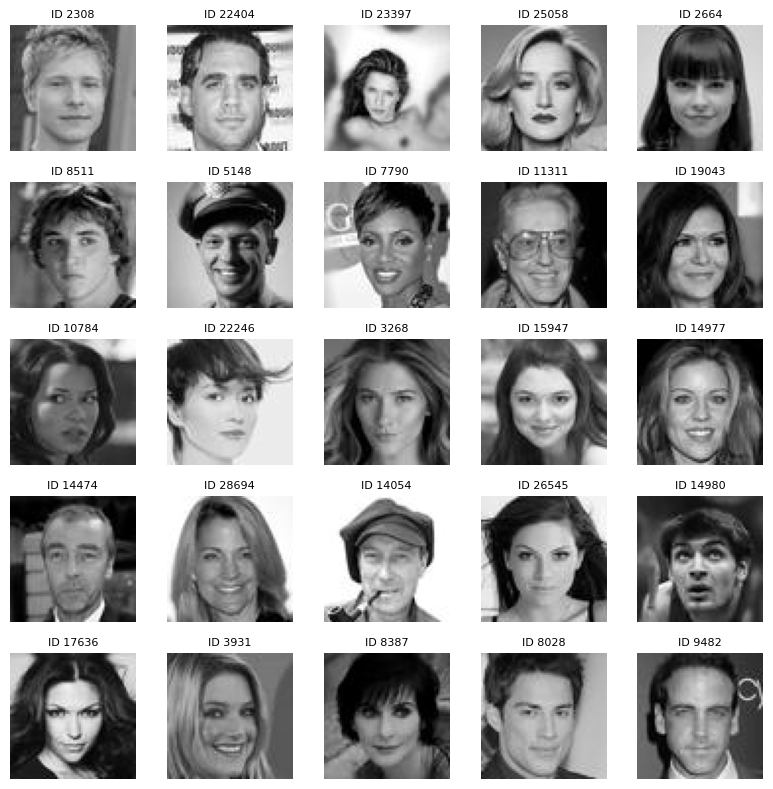

In [ ]:
# Visualización rápida
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# La misma semilla fija el split y el shuffle
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [77]:
# Normalizamos a [0,1] y separamos 27.000 imágenes para train y 3.000 para validación

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

# La partición se hace sobre índices para mantener correspondencia con las imágenes originales
val_size = int(VAL_FRACTION * len(x_data))
# Mix de índices
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


---

## **3. Modelo (encoder, decoder, autoencoder)**

El modelo es un AE determinista formado por un encoder convolucional, un vector latente de `LATENT_DIM = 128` dimensiones y un decoder convolucional. El encoder comprime cada imagen de `64x64x1` hasta un mapa de `4x4` y después hasta el vector `z`; el decoder realiza el recorrido inverso y produce una imagen en `[0, 1]` mediante una salida `sigmoid`.

La arquitectura no contiene un GMM, un VAE ni ningún otro modelo generativo. Para que el muestreo normal estándar sea una aproximación razonable, el espacio latente se estandariza después de la capa `Dense` mediante `BatchNormalization(center=False, scale=False)`. Esta capa centra y normaliza cada dimensión usando las estadísticas del batch, y durante inferencia usa las estadísticas acumuladas. En futuros notebooks, eliminaremos esta capa para no perder información de escala y centro, y estudiaremos otras formas de regularizar el espacio latente.

In [78]:
# Encoder 
encoder_inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 1),
    name="encoder_input"
)

x = layers.Conv2D(32, kernel_size=4, strides=2, padding="same", use_bias=False)(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Flatten()(x)

# Proyección final a 128 coordenadas latentes antes de la estandarización.
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector"
)(x)

# Normalización sin centro ni escala: aproxima media 0 y varianza 1 por dimensión.
z = layers.BatchNormalization(
    center=False,
    scale=False,
    name="latent_standardization"
)(z)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_135 (Conv2D)             │ (None, 32, 32, 32)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_138         │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_44 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_136 (Conv2D)             │ (None, 16, 16, 64)     │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_139         │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_45 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_137 (Conv2D)             │ (None, 8, 8, 128)      │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_140         │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_46 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_138 (Conv2D)             │ (None, 4, 4, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_141         │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_47 (LeakyReLU)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_standardization          │ (None, 128)            │           256 │
│ (BatchNormalization)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,215,232 (4.64 MB)

 Trainable params: 1,214,016 (4.63 MB)

 Non-trainable params: 1,216 (4.75 KB)

In [79]:
# Decoder 
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

# Expandimos z a la última activación 4x4x256 del encoder
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

# Cada bloque duplica la resolución: 4 -> 8 -> 16 -> 32 -> 64
for filters in (128, 64, 32, 16):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

# La última convolución produce una intensidad por píxel en [0,1]
decoder_outputs = layers.Conv2D(
    1,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="decoder_output"
)(x)

decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_142         │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_48 (LeakyReLU)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_12 (UpSampling2D) │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_139 (Conv2D)             │ (None, 8, 8, 128)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_143         │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_49 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_13 (UpSampling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_140 (Conv2D)             │ (None, 16, 16, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_144         │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_50 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_14 (UpSampling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_141 (Conv2D)             │ (None, 32, 32, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_145         │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_51 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_15 (UpSampling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_142 (Conv2D)             │ (None, 64, 64, 16)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_146         │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_52 (LeakyReLU)      │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 64, 64, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 933,457 (3.56 MB)

 Trainable params: 924,785 (3.53 MB)

 Non-trainable params: 8,672 (33.88 KB)

In [80]:
# Modelo completo: imagen -> encoder -> z -> decoder -> imagen.
encoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="autoencoder_input")
autoencoder = keras.Model(
    encoder_input,
    decoder_ae(encoder_ae(encoder_input)),
    name="autoencoder"
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 128)            │     1,215,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 1)      │       933,457 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,148,689 (8.20 MB)

 Trainable params: 2,138,801 (8.16 MB)

 Non-trainable params: 9,888 (38.62 KB)

#### **Cuello de botella**

Se pasa de `4096` píxeles a `128` números: una compresión de `32x`. El latente limita el nivel de detalle que el decoder puede recuperar y, por tanto, la calidad de las reconstrucciones: es un **candidato a ampliarse**. Además, la `Dense` `4096 -> 128` concentra una parte importante de los parámetros del encoder y decoder `Dense` `128 -> 4096`.

#### **Encoder y normalización interna**

- **Encoder convolucional:** cuatro bloques `Conv2D` con filtros `32, 64, 128 y 256` y `stride=2`. Cada bloque reduce la resolución espacial a la mitad: `64 -> 32 -> 16 -> 8 -> 4` (salta cada 2 pixeles en vertical y horizontal), mientras aumenta el número de canales para captar patrones cada vez más abstractos.
- **Normalización interna:** `BatchNormalization` y `LeakyReLU` se usan para estabilizar el entrenamiento y mantener gradientes aceptables aunque haya algunas activaciones negativas (multiplicamos por 0.2 la pendiente de la parte negativa para no saturar a 0 la neurona como en una ReLU).
- **Espacio latente:** la activación `4x4x256` se aplana y pasa a una `Dense` de `128` dimensiones con regularización L2.

#### **Para qué sirve el BN del latente y cuáles son sus límites**

Después de la `Dense` se hace un `BatchNormalization(center=False, scale=False)`. Estandariza **cada dimensión por separado** (media `0`, varianza `1`) ya que, si cada coordenada tiene aproximadamente esa escala, `N(0, I)` será una aproximación más coherente para generar. Más adelante explicaremos por qué es necesario generar imágenes a partir de un espacio latente que comparta las mismas estadísticas con las que el decoder fue entrenado.

Problemas:

- **No garantiza independencia** entre dimensiones: pueden existir correlaciones entre coordenadas.
- **No garantiza forma gaussiana**: la media y la varianza no determinan la distribución (puede tener colas pesadas).
- **No garantiza que las estadísticas de inferencia coincidan con las del batch**: en entrenamiento se usan medias y varianzas del batch; en inferencia, las acumuladas.

Esto se tratará en el próximo notebook: en lugar de apoyarse en la BN, se ajustará una distribución sobre `z_train` (normal multivariante con covarianza, GMM, kNN, etc). 

#### **Decoder**

- **Decoder:** proyecta el vector latente `z` mediante una `Dense` a un mapa `4x4x256`. Después, cuatro bloques formados por `UpSampling2D` bilineal y `Conv2D` van duplicando la resolución: `4 -> 8 -> 16 -> 32 -> 64`.
- **Diseño (bilineal + `Conv2D` vs `Conv2DTranspose`):** `Conv2DTranspose` aprende a la vez cómo ampliar y cómo rellenar los píxeles nuevos y, si el tamaño del filtro no es divisible por el stride, algunas zonas reciben más solapamiento que otras, lo que puede producir píxeles demasiado brillantes u oscuros, sobre todo en bordes. Con interpolación bilineal la imagen se amplía promediado los vecinos más cercanos y la convolución posterior refina los detalles. 
- **Salida:** una convolución final con `sigmoid` devuelve valores en `[0, 1]`, que luego se convierten a `[0, 255]` para la submission.
- El decoder es otro **candidato a ampliarse** (más filtros, más profundidad, bloques residuales, etc).

---

## **4. Pérdida y entrenamiento (+ guardado y carga de modelos)**

### **Decisiones de pérdida y entrenamiento**

La pérdida es la media de dos objetivos, `0.5·L1 + 0.5·(1 - SSIM)`:

- **L1:** penaliza el error absoluto por píxel y tiende a conservar bordes sin ajustarnos demasiado a errores aislados.
- **SSIM:** compara la estructura y contraste para que las reconstrucciones mantengan la estructura aunque no coincidan exactamente en cada píxel.

**Por qué no MSE**: El MSE penaliza cuadráticamente los errores, de modo que un error grande pesa mucho más que varios pequeños; ante varias reconstrucciones con sentido tiende a promediarlas y a producir imágenes suaves para que el error sea menor. L1 tiene más indiferencia frente a valores atípicos. 

**Límite**: Ninguna de las dos pérdidas mide lo mismo que el `FID`: el FID compara distribuciones de características de Inception sobre *conjuntos* de imágenes, mientras que la pérdida compara cada imagen con su propia reconstrucción. Una pérdida de reconstrucción baja **no implica** un FID bajo del muestreo (la reconstrucción no pasa por el muestreo del latente). Por eso el FID se evalúa aparte y, como trabajo futuro, convendría monitorizar durante el entrenamiento una métrica próxima al FID.

**Data Augmentation**: Con `tf.image.random_flip_left_right` se voltea horizontalmente la imagen de entrada en el conjunto de entrenamiento, y la imagen volteada se usa también como objetivo (entrada y objetivo son la misma imagen volteada). Duplica la variedad de datos de entrenamiento. La validación no se aumenta ni se baraja. Con tantos datos y tan variados, el aumento de datos no es crítico, pero sí ayuda a que el modelo generalice mejor y no memorice la posición de los ojos, boca o nariz.

**Callbacks**: `ReduceLROnPlateau` reduce la tasa de aprendizaje si `val_loss` deja de mejorar y `EarlyStopping` recoje los mejores pesos de entrenamiento. Usar `val_loss` como criterio también tiene límites: es una pérdida de reconstrucción (no mide la calidad del muestreo ni el FID), se calcula sobre el mismo conjunto de validación que luego sirve de referencia para el FID, y sus diferencias pequeñas entre épocas pueden ser ruido, de modo que la mejor época es una elección algo arbitraria.

### **Guardado y carga de modelos**
Tras entrenar se guardan el autoencoder, el encoder, el decoder y el historial. Con `TRAIN_MODEL = False` se cargan con `keras.models.load_model(path, compile=False)` (la pérdida es una función propia que no hace falta recompilar para predecir). Con `TRAIN_MODEL = True`, una celda recarga lo ya guardado y comprueba que el decoder produce las mismas salidas que el decoder en memoria.

In [ ]:
# Pérdida: L1 para precisión de píxel y SSIM para estructura
# Se calcula por batch y se promedian los términos
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(
        tf.image.ssim(y_true, y_pred, max_val=1.0)
    )
    return 0.5 * l1 + 0.5 * ssim

# Adam como optimizador
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=ssim_l1_loss
)


def make_dataset(x_array, training=True):
    dataset = tf.data.Dataset.from_tensor_slices((x_array, x_array))
    # Solo train recibe shuffle y flip, validation es determinista
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(x_array), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            lambda image, target: (
                tf.image.random_flip_left_right(image),
                target
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        # Entrada y objetivo son la misma imagen volteada
        dataset = dataset.map(
            lambda image, _: (image, image),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(x_train, training=True)
val_ds = make_dataset(x_val, training=False)

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

In [82]:
# Entrenamiento si TRAIN_MODEL = True
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        train_ds,
        epochs=EPOCHS,
        validation_data=val_ds,
        callbacks=callbacks
    )
else:
    print("TRAIN_MODEL = False: no se entrena; los modelos se cargan en la celda de carga.")

Epoch 1/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 45s 193ms/step - loss: 0.3593 - val_loss: 0.4568 - learning_rate: 0.0010
Epoch 2/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 39s 184ms/step - loss: 0.2566 - val_loss: 0.3097 - learning_rate: 0.0010
Epoch 3/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 38s 179ms/step - loss: 0.2285 - val_loss: 0.2198 - learning_rate: 0.0010
Epoch 4/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 39s 185ms/step - loss: 0.2127 - val_loss: 0.2072 - learning_rate: 0.0010
Epoch 5/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 39s 183ms/step - loss: 0.2023 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 6/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 38s 181ms/step - loss: 0.1942 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 7/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 39s 184ms/step - loss: 0.1888 - val_loss: 0.1899 - learning_rate: 0.0010
Epoch 8/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 41s 195ms/step - loss: 0.1833 - val_loss: 0.1805 - learning_rate: 0.0010
Epoch 9/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 42s 199ms/step - loss: 0.1794 - val_loss: 0.1843 - learn

In [104]:
# Guardar los modelos para poder reutilizar
if TRAIN_MODEL:
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    print(f"Modelos guardados en {CHECKPOINT_DIR}/")

Modelos guardados en checkpoints/


In [105]:
# Guardar el historial de entrenamiento como JSON 
if TRAIN_MODEL:
    history_dict = {
        key: [float(v) for v in values]
        for key, values in history_ae.history.items()
    }
    with open(HISTORY_PATH, "w") as f:
        json.dump(history_dict, f, indent=2)
    print(f"Historial guardado en {HISTORY_PATH}")

Historial guardado en checkpoints/ae_complex1_history.json


In [106]:
# Carga (TRAIN_MODEL=False) o verificación del guardado (TRAIN_MODEL=True)
if not TRAIN_MODEL:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [p for p in required if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(
            f"TRAIN_MODEL=False pero faltan ficheros guardados: {missing}. "
            "Ejecuta una vez con TRAIN_MODEL=True para entrenar y guardarlos."
        )

    # compile=False: la pérdida no hace falta para predecir
    autoencoder = keras.models.load_model(AE_PATH, compile=False)
    encoder_ae = keras.models.load_model(ENCODER_PATH, compile=False)
    decoder_ae = keras.models.load_model(DECODER_PATH, compile=False)
    with open(HISTORY_PATH) as f:
        history_ae = SimpleNamespace(history=json.load(f))

    print("Modelos cargados desde disco, no se ha entrenado en esta ejecución.")
    print(f"  autoencoder: {AE_PATH}")
    print(f"  encoder:     {ENCODER_PATH}")
    print(f"  decoder:     {DECODER_PATH}")
    print(f"  historial:   {HISTORY_PATH} ({len(history_ae.history['loss'])} épocas)")
else:
    VERIFY_SAVE = True
    if VERIFY_SAVE:
        z_check = np.random.default_rng(SAMPLE_SEED).normal(
            size=(8, LATENT_DIM)
        ).astype(np.float32)
        decoder_reloaded = keras.models.load_model(DECODER_PATH, compile=False)
        same = np.allclose(
            decoder_ae.predict(z_check, verbose=0),
            decoder_reloaded.predict(z_check, verbose=0),
            atol=1e-6
        )
        assert same, "El decoder recargado no coincide con el decoder en memoria."
        print("Verificación OK: decoder recargado == decoder en memoria (8 muestras fijas).")

Verificación OK: decoder recargado == decoder en memoria (8 muestras fijas).


---

## **5. Resultados del entrenamiento y reconstrucciones**

Las siguientes celdas muestran el comportamiento de las reconstrucciones, un resumen de la mejor época según `val_loss` y la evolución de la pérdida. 

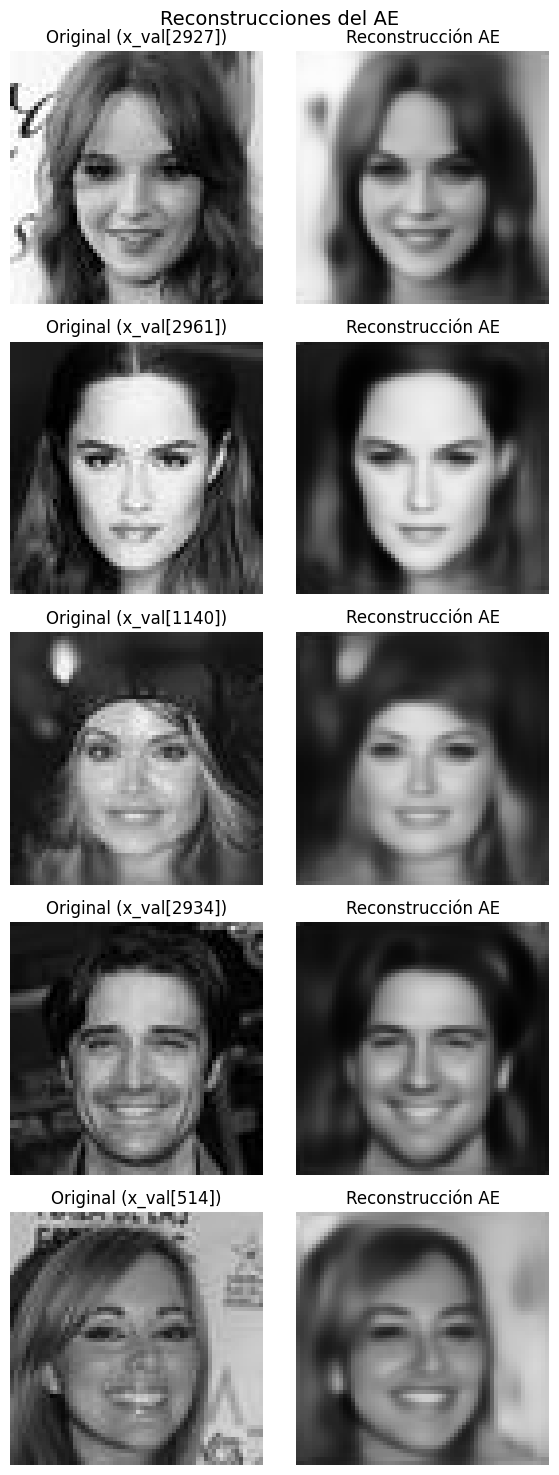

In [ ]:
# Estas imágenes no se usan para entrenar ni generar la submission
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)

comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

ae_reconstructions = autoencoder.predict(x_val_samples, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del AE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, ae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción AE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [108]:
# Resumen de la mejor epoch según la pérdida de validación
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 60
Train loss:      0.1392
Validation loss: 0.1383


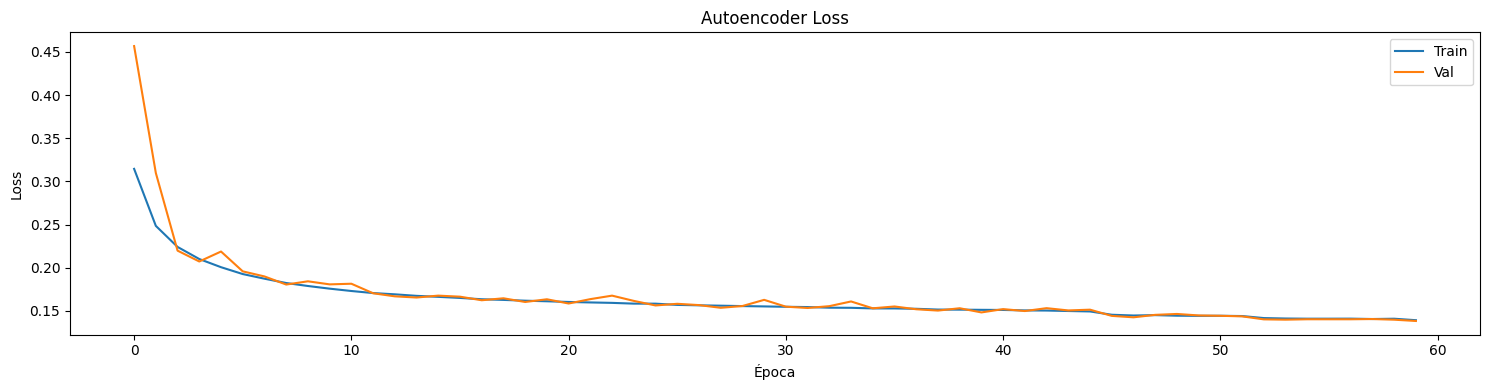

In [109]:
# Curvas para detectar convergencia y posible overfitting
fig, axes = plt.subplots(1, figsize=(15, 4))

axes.plot(history_ae.history["loss"], label="Train")
axes.plot(history_ae.history["val_loss"], label="Val")
axes.set_title("Autoencoder Loss")
axes.set_xlabel("Época")
axes.set_ylabel("Loss")
axes.legend()

plt.tight_layout()
plt.show()

---

## **6. Generación y creación de la submission**

El decoder se utiliza como único modelo generativo. Se generan `N_SAMPLES = 200` vectores latentes con una normal estándar y se decodifican directamente:

```text
z ~ N(0, I) -> decoder_ae -> imagen
```

La estandarización del espacio latente hace que esta elección sea más defendible que en un AE sin normalización, pero las correlaciones, la geometría global y la distribución del latente siguen siendo aproximaciones. 

Las imágenes de validación no se usan para generar la submission. Solo se emplean para evaluación y como referencia real del FID.

In [110]:
# N_SAMPLES y SAMPLE_SEED de la configuración común
sample_rng = np.random.default_rng(SAMPLE_SEED)
z_samples_ae = sample_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

print(f"Muestras latentes generadas: {z_samples_ae.shape}")

Muestras latentes generadas: (200, 128)


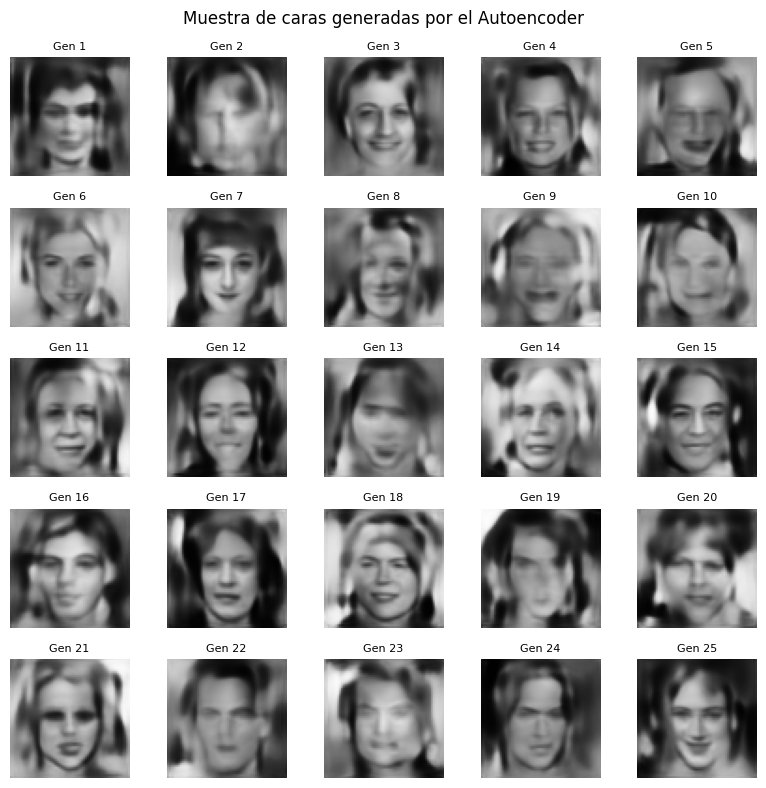

In [ ]:
# El decoder devuelve float32 en [0, 1], así que modificamos para visualizar en [0, 255]
generated_float = decoder_ae.predict(
    z_samples_ae,
    batch_size=N_SAMPLES,
    verbose=0
)
generated_imgs = np.clip(
    np.round(generated_float * 255.0), 0, 255
).astype(np.uint8)
generated_imgs = np.squeeze(generated_imgs, axis=-1)

assert generated_float.shape == (N_SAMPLES, IMG_SIZE, IMG_SIZE, 1)
assert np.isfinite(generated_float).all()
assert generated_float.min() >= 0.0 and generated_float.max() <= 1.0

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el Autoencoder", fontsize=12)
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)
plt.tight_layout()
plt.show()


In [112]:
# Exportación: solo estas 200 imágenes generadas se pasan al formato de entrega
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)
df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

assert df_submission.shape == (N_SAMPLES, 1 + IMG_SIZE * IMG_SIZE)
assert df_submission.isnull().sum().sum() == 0
assert df_submission.iloc[:, 1:].values.min() >= 0
assert df_submission.iloc[:, 1:].values.max() <= 255
assert list(df_submission.columns[:2]) == ["ID", "0"]

os.makedirs(SUBMISSIONS_DIR, exist_ok=True)
csv_filename = f"{SUBMISSIONS_DIR}/submission_{NOTEBOOK_NAME}.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}' | forma: {df_submission.shape}")

Archivo guardado como 'submissions/submission_ae_complex1.csv' | forma: (200, 4098)


---

## **7. Evaluación FID**

La referencia real es `x_val`, se convierten las imágenes grayscale a `uint8`, se replica el canal gris a RGB y se usa `feature=2048`. Se calcula con dos tamaños: `FID_NUM_IMAGES_REF = 512` y `FID_NUM_IMAGES_SUBMISSION = 200`.

- **200 imágenes** es el tamaño de la submission.
- **512 imágenes** es más estable estadísticamente.
- **FID con distinto N no son comparables entre sí.** El FID con pocas imágenes está sesgado al alza y es ruidoso.

Las reconstrucciones sirven como techo aproximado de la capacidad de reconstrucción, mientras que el FID de muestras normales evalúa además si el muestreo elegido cubre el espacio latente.

In [ ]:
FID_SEED = SEED

device = "cpu"

def prepare_images_for_fid(images):
    images = np.asarray(images)
    
    # Si la imagen ya es uint8, asumimos que está en [0, 255]
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
        
    if images.ndim == 3:
        images = images[..., np.newaxis]
        
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    # Inception convierte cada imagen en un vector de características; FID compara sus medias/covarianzas
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(device), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(device), real=False)
        return fid.compute().item()


def generate_normal_samples(n, sigma=1.0):
    # z ~ N(0, sigma^2 I) -> decoder. Con sigma=1 es el muestreo estándar del baseline
    fid_rng = np.random.default_rng(FID_SEED)
    z_fid = fid_rng.normal(
        0.0, sigma, size=(n, LATENT_DIM)
    ).astype(np.float32)
    return decoder_ae.predict(z_fid, batch_size=FID_BATCH_SIZE, verbose=0)


def fid_normal_sampling(n, sigma=1.0):
    # Referencia real, únicamente validación
    n = min(len(x_val), n)
    return calculate_fid(
        generate_normal_samples(n, sigma),
        x_val[:n],
        batch_size=FID_BATCH_SIZE
    )

In [114]:
# FID del muestreo N(0, I) con ambos tamaños, con las mismas funciones y la misma referencia
fid_results = {}
for n_images in (FID_NUM_IMAGES_REF, FID_NUM_IMAGES_SUBMISSION):
    fid_results[n_images] = fid_normal_sampling(n_images)
    print(f"FID AE N(0, I) ({min(len(x_val), n_images)} imágenes, dispositivo={device}): {fid_results[n_images]:.4f}")

fid_512 = fid_results[FID_NUM_IMAGES_REF]
fid_200 = fid_results[FID_NUM_IMAGES_SUBMISSION]

FID AE N(0, I) (512 imágenes, dispositivo=cpu): 114.9284
FID AE N(0, I) (200 imágenes, dispositivo=cpu): 131.9774


In [115]:
os.makedirs(RESULTS_DIR, exist_ok=True)
metrics = {
    "fid_200": float(fid_200),
    "fid_512": float(fid_512),
    "best_epoch": int(best_epoch + 1),  
    "train_loss": float(metrics_history["loss"][best_epoch]),
    "val_loss": float(metrics_history["val_loss"][best_epoch]),
    "latent_dim": int(LATENT_DIM),
    "n_params": int(autoencoder.count_params()),
    "sampling_method": "N(0, I)",  
}
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)
print(f"Métricas guardadas en {METRICS_PATH}")
print(json.dumps(metrics, indent=2))

Métricas guardadas en results/ae_complex1_metrics.json
{
  "fid_200": 131.97743225097656,
  "fid_512": 114.92842102050781,
  "best_epoch": 60,
  "train_loss": 0.13921035826206207,
  "val_loss": 0.138313889503479,
  "latent_dim": 128,
  "n_params": 2148689,
  "sampling_method": "N(0, I)"
}


---

## **8. Diagnóstico del espacio latente**

1. **¿Se parece `z_train` a una `N(0, I)`?** Se codifica `x_train` con el encoder (sin flip) y se resumen la media y la desviación por dimensión, la norma de los códigos frente a la esperada para una `N(0, I)` (≈ `√128`) y las correlaciones entre dimensiones.

2. **¿Cuánto se pierde por el muestreo y cuánto por el decoder?** El FID de las reconstrucciones de validación estima el techo de este decoder con latentes reales; la diferencia con el FID del muestreo `N(0, I)` mide la pérdida atribuible al muestreo. (La referencia `x_val[:N]` contiene las mismas imágenes que se reconstruyen, por lo que este techo es optimista).

z_train: (27000, 128)
Media por dimensión  -> min -0.085 | mediana -0.001 | max +0.114
Desv. por dimensión  -> min 0.970 | mediana 0.989 | max 1.009
Norma media de z_train: 11.104 (esperada para N(0, I): ~sqrt(128) = 11.314)
Correlación |r| fuera de la diagonal -> media 0.0652 | máx 0.6339


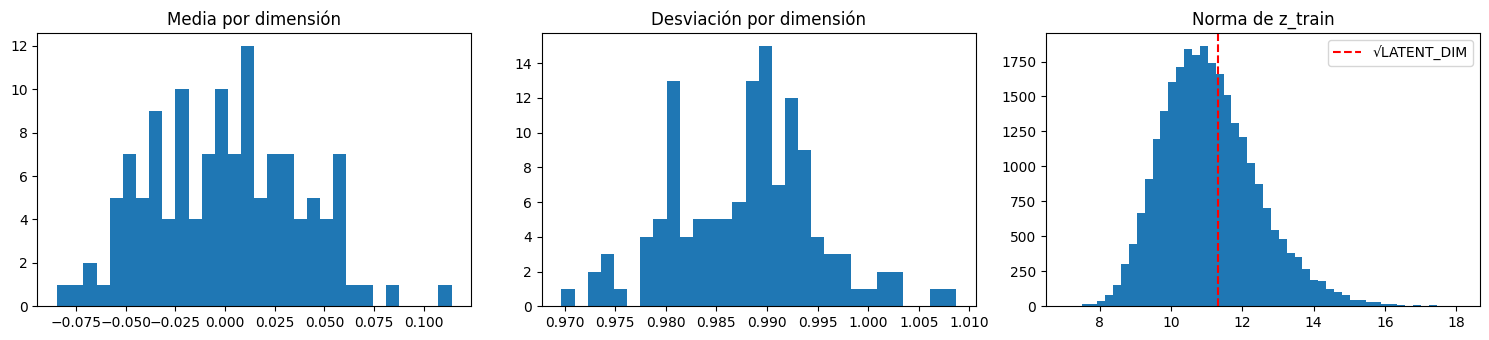

In [116]:
z_train = encoder_ae.predict(x_train, batch_size=BATCH_SIZE, verbose=0)

z_mean = z_train.mean(axis=0)
z_std = z_train.std(axis=0)
print(f"z_train: {z_train.shape}")
print(f"Media por dimensión  -> min {z_mean.min():+.3f} | mediana {np.median(z_mean):+.3f} | max {z_mean.max():+.3f}")
print(f"Desv. por dimensión  -> min {z_std.min():.3f} | mediana {np.median(z_std):.3f} | max {z_std.max():.3f}")

norms = np.linalg.norm(z_train, axis=1)
print(f"Norma media de z_train: {norms.mean():.3f} (esperada para N(0, I): ~sqrt({LATENT_DIM}) = {np.sqrt(LATENT_DIM):.3f})")

corr = np.corrcoef(z_train, rowvar=False)
off_diag = np.abs(corr[~np.eye(LATENT_DIM, dtype=bool)])
print(f"Correlación |r| fuera de la diagonal -> media {off_diag.mean():.4f} | máx {off_diag.max():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(z_mean, bins=30)
axes[0].set_title("Media por dimensión")
axes[1].hist(z_std, bins=30)
axes[1].set_title("Desviación por dimensión")
axes[2].hist(norms, bins=50)
axes[2].axvline(np.sqrt(LATENT_DIM), color="r", linestyle="--", label="√LATENT_DIM")
axes[2].set_title("Norma de z_train")
axes[2].legend()
plt.tight_layout()
plt.show()

In [119]:
# Techo del decoder frente al muestreo N(0, I).
for n_images in (FID_NUM_IMAGES_REF, FID_NUM_IMAGES_SUBMISSION):
    n = min(len(x_val), n_images)
    recon = autoencoder.predict(x_val[:n], batch_size=FID_BATCH_SIZE, verbose=0)
    fid_recon = calculate_fid(recon, x_val[:n], batch_size=FID_BATCH_SIZE)
    fid_sample = fid_results[n_images]
    print(f"N={n}: FID reconstrucciones = {fid_recon:.4f} | FID N(0, I) = {fid_sample:.4f} | "
          f"diferencia (coste del muestreo) = {fid_sample - fid_recon:.4f}")

N=512: FID reconstrucciones = 90.4634 | FID N(0, I) = 114.9284 | diferencia (coste del muestreo) = 24.4651
N=200: FID reconstrucciones = 104.0617 | FID N(0, I) = 131.9774 | diferencia (coste del muestreo) = 27.9157


### **Interpretación de los resultados**

Como podemos ver, hemos conseguido que los latentes tengan media y varianza cercanas a las de una normal estándar, para que la reconstrucción tenga sentido, pero no son independientes ni gausianos. El **FID** de las reconstrucciones es mucho mejor que el del muestreo, lo que indica que el decoder es capaz de reconstruir de forma aceptable a partir de latentes reales, pero que el muestreo `N(0, I)` no cubre bien el espacio latente. 

El FID de esta entrega dio 126 en Kaggle.

---

## **9. Hoja de ruta**

1. **Tamaño del latente** `128` puede ser aumentado a `256` o `512` para que el decoder tenga más información y produzca reconstrucciones más nítidas.
2. **Capacidad del decoder**: relativamente pequeño y con pocos filtros en las últimas capas.
3. **Método de muestreo**: `N(0, I)` apoyado en una BN que solo estandariza por dimensión.
4. **Desalineación entre la pérdida de reconstrucción y el FID**: minimizar la reconstrucción no optimiza directamente la calidad de las muestras.